_Transaction records for Maven Roasters, a fictitious coffee shop operating out of three NYC locations. Dataset includes the transaction date, timestamp and location, along with product-level details._

### Recommended Analysis
* How have Maven Roasters sales trended over time?
* Which days of the week tend to be busiest, and why do you think that's the case?
* What times of day tend to be most popular? Does the same trend hold across all locations?
* Which products are sold most and least often? Which drive the most revenue for the business?

In [2]:
import pandas as pd
import os
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:


# Lee el Excel directamente (sin necesitar Excel instalado)
df = pd.read_excel("coffee_sales/coffee_sales.xlsx")


In [4]:
print(df.head())
print(df.shape)

   transaction_id transaction_date transaction_time  transaction_qty  \
0               1       2023-01-01         07:06:11                2   
1               2       2023-01-01         07:08:56                2   
2               3       2023-01-01         07:14:04                2   
3               4       2023-01-01         07:20:24                1   
4               5       2023-01-01         07:22:41                2   

   store_id   store_location  product_id  unit_price    product_category  \
0         5  Lower Manhattan          32         3.0              Coffee   
1         5  Lower Manhattan          57         3.1                 Tea   
2         5  Lower Manhattan          59         4.5  Drinking Chocolate   
3         5  Lower Manhattan          22         2.0              Coffee   
4         5  Lower Manhattan          57         3.1                 Tea   

            product_type               product_detail  
0  Gourmet brewed coffee                  Ethiopia Rg 

In [5]:
df[df.isna().any(axis=1)]
print(df.dtypes)

transaction_id               int64
transaction_date    datetime64[ns]
transaction_time            object
transaction_qty              int64
store_id                     int64
store_location              object
product_id                   int64
unit_price                 float64
product_category            object
product_type                object
product_detail              object
dtype: object


# Q1: How have Maven Roasters sales trended over time?

Necesitamos graficar transaction_date vs. el producto entre unit_price*transaction_qty


In [6]:
df["total_amount"] = df["transaction_qty"] * df["unit_price"]
df["day_of_the_week"]= df["transaction_date"].dt.day_name()
df["month"]=df["transaction_date"].dt.month_name()
df["hour"]=(pd.to_datetime(df["transaction_time"], format='%H:%M:%S')).dt.hour


In [7]:
df.head()

,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail,total_amount,day_of_the_week,month,hour
0,1,2023-01-01,07:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg,6.0,Sunday,January,7
1,2,2023-01-01,07:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg,6.2,Sunday,January,7
2,3,2023-01-01,07:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg,9.0,Sunday,January,7
3,4,2023-01-01,07:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm,2.0,Sunday,January,7
4,5,2023-01-01,07:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg,6.2,Sunday,January,7


In [8]:
#Datos atipicos, parecen artificiales
mediana = df['total_amount'].median()
df['total_amount_original'] = df['total_amount']  # respaldo
df.loc[df['total_amount'] > 300, 'total_amount'] = mediana

<Axes: xlabel='month', ylabel='Revenue'>

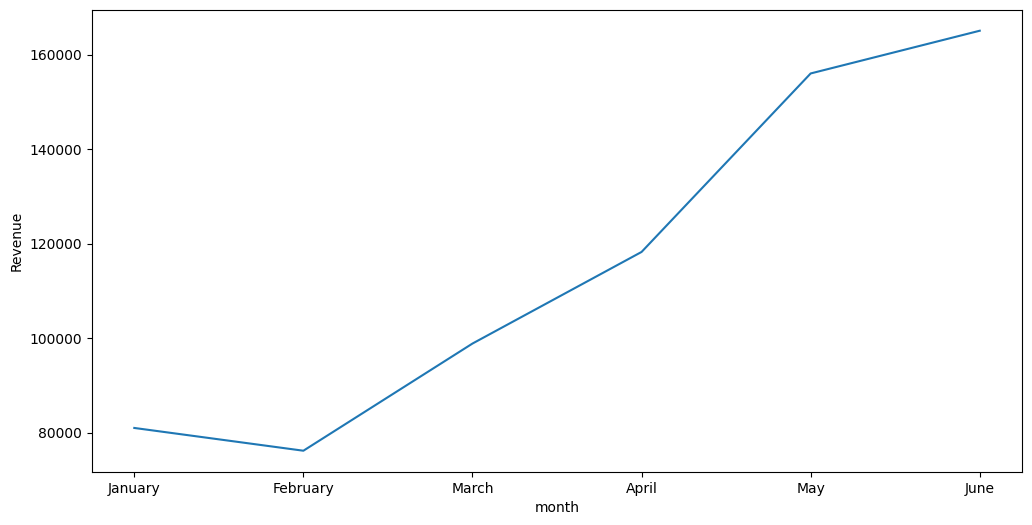

In [9]:
orden_meses = ['January', 'February', 'March', 'April', 'May', 'June', 
               'July', 'August', 'September', 'October', 'November', 'December']
df['month'] = pd.Categorical(df['month'], categories=orden_meses, ordered=True)
df_month = df.groupby('month', observed=True)['total_amount'].sum().reset_index(name='Revenue')

plt.figure(figsize=(12,6))
sns.lineplot(df_month, x = "month", y = "Revenue" )

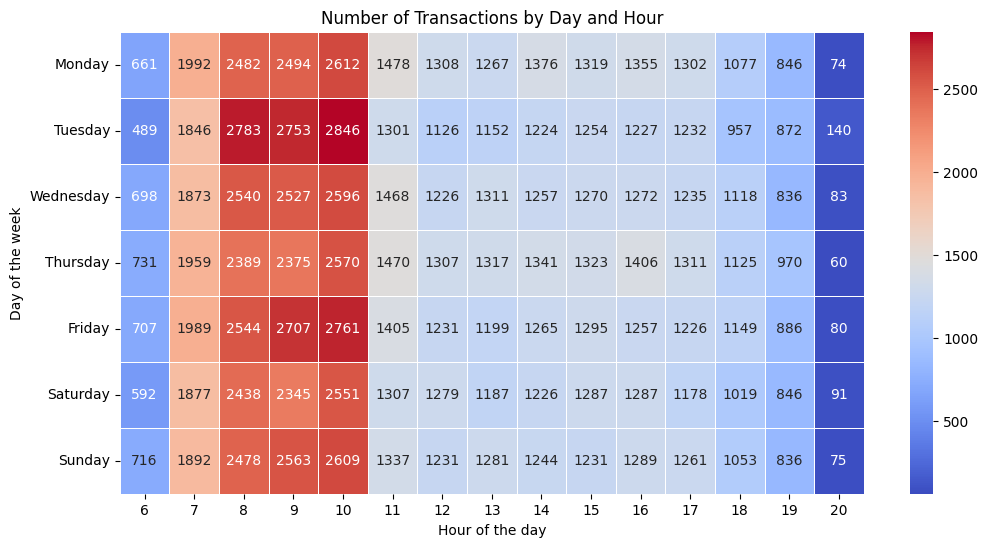

In [10]:
df_hour_and_day = df.groupby(['day_of_the_week','hour']).size().reset_index(name='num_registros')

# Pivotear: filas = día, columnas = hora, valores = num_registros
pivot = df_hour_and_day.pivot(index='day_of_the_week', columns='hour', values='num_registros')

# Ordenar los días de la semana correctamente (por defecto pandas los ordena alfabéticamente)
orden_dias = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
pivot = pivot.reindex(orden_dias)

plt.figure(figsize=(12, 6))
sns.heatmap(pivot, cmap='coolwarm', annot=True, fmt='.0f', linewidths=0.5)
plt.title('Number of Transactions by Day and Hour')
plt.xlabel('Hour of the day')
plt.ylabel('Day of the week')
plt.show()


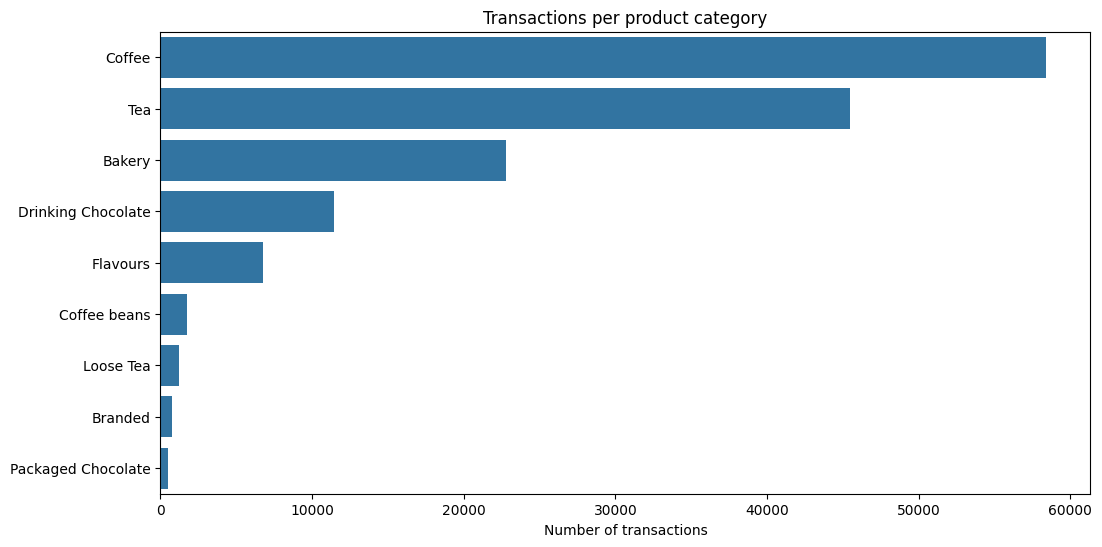

In [11]:
df_product_category = df.groupby('product_category').size().reset_index(name='Num_Register').sort_values('Num_Register', ascending=False) 
df_product_category
plt.figure(figsize=(12, 6))
sns.barplot(df_product_category, x= "Num_Register", y= "product_category")
plt.title('Transactions per product category')
plt.xlabel('Number of transactions')
plt.ylabel('')
plt.show()


In [12]:
df_top_products = df.groupby('product_type')['total_amount'].agg(Total_revenue='sum', num_transacciones='size').reset_index().sort_values('Total_revenue', ascending=False)
df_top_products 

,product_type,Total_revenue,num_transacciones
0,Barista Espresso,91406.20,16403
4,Brewed Chai tea,77081.95,17183
17,Hot chocolate,72416.00,11468
13,Gourmet brewed coffee,70034.60,16912
3,Brewed Black tea,47932.00,11350
6,Brewed herbal tea,47539.50,11245
25,Premium brewed coffee,38781.15,8135
22,Organic brewed coffee,37746.50,8489
27,Scone,36866.12,10173
10,Drip coffee,31984.00,8477


In [16]:
df.head()
df.to_csv('coffee_sales_clean.csv', index=False, decimal=',', sep=';')